In [1]:
import numpy as np
import math as mp
import pandas as pd

/Users/samuelzhao/anaconda3/lib/python3.10/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [2]:
sigma = 5
beta = 1 /( 1.0 +0.01)
beta1 =1/( (1.0 +0.01* np.exp(30/(36.5*0.9)))) 
power = (1+1)/(-1-1)
W = 1

/var/folders/26/bmvk0hrd5xbgcvl_s6s42rf80000gn/T/ipykernel_5432/2773425506.py:1: FutureWarning: The argument 'infer_datetime_format' is deprecated and will be removed in a future version. A strict version of it is now the default, see https://pandas.pydata.org/pdeps/0004-consistent-to-datetime-parsing.html. You can safely remove this argument.
  data=pd.read_csv('APP_data_usa_goods.csv', index_col=0, parse_dates=True, infer_datetime_format=True)
/var/folders/26/bmvk0hrd5xbgcvl_s6s42rf80000gn/T/ipykernel_5432/2773425506.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  data=pd.read_csv('APP_data_usa_goods.csv', index_col=0, parse_dates=True, infer_datetime_format=True)


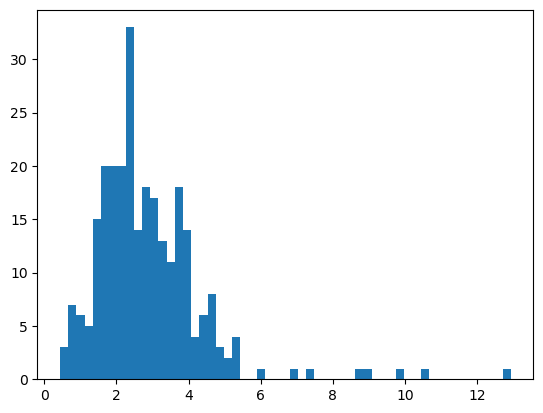

In [3]:
data=pd.read_csv('APP_data_usa_goods.csv', index_col=0, parse_dates=True, infer_datetime_format=True)
data_tau=(data['invtCogsRatio']* 36.5/(30*0.1))
import matplotlib.pyplot as plt
plt.hist(data_tau,bins = 55)
plt.show()

In [4]:
tau_diff = np.zeros(( 1000,1))
i = 0
for c in np.linspace(0, 0.99, 1000): 
    N = -(data_tau) - 1/np.log(beta*c) 
    tau1= -1/np.log(beta*c) - N
    tau1[tau1<0] = 0     
    tau2= -1/np.log(beta1*c) - N
    tau2[tau2<0] = 0    
    tau_diff[i] = np.mean(np.abs(tau1-tau2))
    i = i+1

/var/folders/26/bmvk0hrd5xbgcvl_s6s42rf80000gn/T/ipykernel_5432/1678760125.py:4: RuntimeWarning: divide by zero encountered in log
  N = -(data_tau) - 1/np.log(beta*c)
/var/folders/26/bmvk0hrd5xbgcvl_s6s42rf80000gn/T/ipykernel_5432/1678760125.py:5: RuntimeWarning: divide by zero encountered in log
  tau1= -1/np.log(beta*c) - N
/var/folders/26/bmvk0hrd5xbgcvl_s6s42rf80000gn/T/ipykernel_5432/1678760125.py:7: RuntimeWarning: divide by zero encountered in log
  tau2= -1/np.log(beta1*c) - N


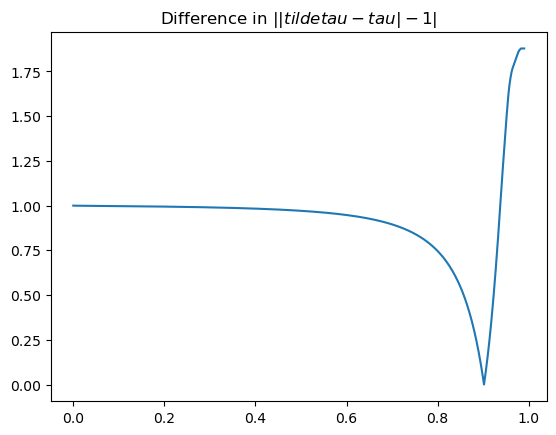

In [5]:
plt.plot(np.linspace(0, 0.99, 1000),np.abs(tau_diff-1))
plt.title('Difference in $||tildetau - tau| -1|$')

plt.show()

In [6]:
min_val = np.min(np.abs(tau_diff-1))
argmins = np.where(np.abs(tau_diff-1) == min_val)[0]

In [7]:
c_list = np.linspace(0, 0.99, 1000)
c= np.min(c_list[argmins])

In [8]:
N=-data_tau - 1/np.log(beta*c) 
tau= -1/np.log(beta*c) - N
tau[tau<0] = 0  
tau_floor = np.floor(tau)
tau_ceil = np.ceil(tau)
tprod_ceil=  (beta*c)**tau_ceil * (tau_ceil + N)
tprod_floor=  (beta*c)**tau_floor * (tau_floor + N)

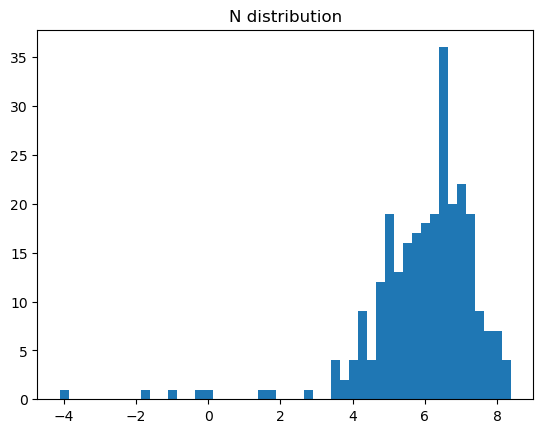

In [9]:
plt.hist(N, bins=50)
plt.title('N distribution')
plt.show()

In [10]:
tau[(tprod_ceil-tprod_floor)>0] = tau_ceil[(tprod_ceil-tprod_floor)>0]
tau[(tprod_ceil-tprod_floor)<0] = tau_floor[(tprod_ceil-tprod_floor)<0]
tau[tau<0] = 0  
tprod = (beta*c)**tau * (tau + N)

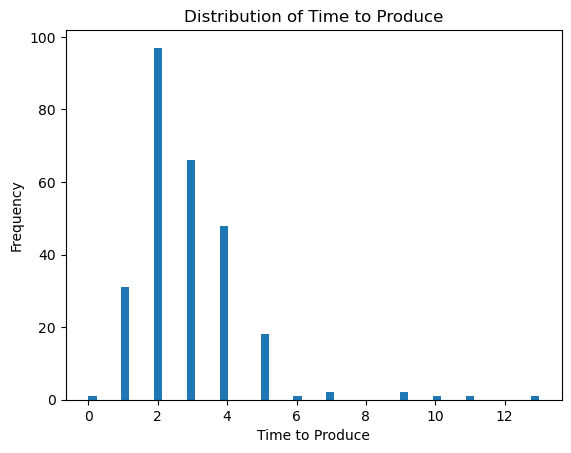

In [11]:
plt.hist(tau, bins = 55, alpha=1, label='tau_noise')
plt.xlabel('Time to Produce')
plt.ylabel('Frequency')
plt.title('Distribution of Time to Produce')
plt.show()

In [12]:
tau = np.array(tau, dtype=int)

In [13]:

def generate_pattern_array_with_extra_rows(tau):
    # 1) Create the original n×n pattern
    n = len(tau)+ int(np.min(tau))
    m = int(np.max(tau)) + int(np.min(tau))

    mx = int(max(tau))
    missing_count = len(set(range(int(max(tau) )+ 1)) - set(tau))


    A = np.ones((m+2, n+missing_count), dtype=float)
    count = 0
    for i in range(1, m+2):
        for j in range(len(tau[tau == i-1])):
            A[i, n- i-j - count] = 0.9 # 0.9 shifts diagonally from right to left as we go down
        if len(tau[tau == i-1]) > 1:
            count += len(tau[tau == i-1])-1
    # 2) Create the two extra rows:
    #    (a) one row with 0.9 at the leftmost column,
    #    (b) one row of all ones.

    row_all_ones = np.ones(n+missing_count, dtype=float)
    A_extended = np.vstack([A,row_all_ones])
    A_extended = A_extended[:,0:n - int(np.min(tau))]

    return A_extended

In [14]:
# Semi-endogenous model: different delta by type
# delta: proportion of firms that cannot change time to build
# In this model, the shock is a productivity decline that ALL firms experience
# But only (1-delta) fraction can adjust their time-to-build in response

def compute_semi_endo_response(N, beta, c, sigma, delta, tau_initial):
    """
    Compute response with semi-endogenous time-to-build
    
    The shock is already embedded in the productivity (A matrix)
    Delta controls what fraction of firms can re-optimize tau after the shock
    
    Parameters:
    - N: array of normalized time-to-build parameters for each firm
    - beta: discount factor  
    - c: cost parameter
    - sigma: elasticity of substitution
    - delta: proportion of firms that cannot adjust tau (0 to 1)
    - tau_initial: pre-shock optimal time-to-build for each firm
    
    Returns:
    - C: consumption response
    - pi: inflation response
    - tau_final: final time-to-build distribution
    """
    # Convert to numpy arrays to avoid pandas indexing issues
    N_arr = np.array(N)
    tau_arr = np.array(tau_initial)
    
    # All firms use the same tau (no re-optimization since shock is in A, not in fundamentals)
    # Delta doesn't matter for impulse response to a common productivity shock
    # It would matter for idiosyncratic shocks or policy changes
    tau_final = tau_arr.copy()
    
    # Reverse for matrix construction  
    tau1 = tau_final[::-1]
    N1_arr = N_arr[::-1]
    tprod1 = np.array((beta * c) ** tau1 * (tau1 + N1_arr))
    
    # Generate price matrix and compute responses
    A = generate_pattern_array_with_extra_rows(tau1)
    P0 = (np.sum(1 / (A * tprod1) ** (1 - sigma), axis=1)) ** (1 / (1 - sigma))
    C = (P0)**power / P0[0]**power - 1
    
    C_padding = np.zeros(len(C) + 1)
    C_padding[1:] = C
    pi = -(C_padding[1:] - C_padding[:-1])
    
    return C, pi, tau_final

In [15]:
tau1 = -1 / np.log(beta * c) - N
tau1[tau1 < 0] = 0
tau1_floor = np.floor(tau1)
tau1_ceil  = np.ceil(tau1)
tprod1_ceil  = (beta * c) ** tau1_ceil  * (tau1_ceil + N)
tprod1_floor = (beta * c) ** tau1_floor * (tau1_floor + N)

tau1[(tprod1_ceil - tprod1_floor) > 0] = tau1_ceil[(tprod1_ceil -
       tprod1_floor) > 0]
tau1[(tprod1_ceil - tprod1_floor) < 0] = tau1_floor[(tprod1_ceil -
tprod1_floor) < 0]
tau1[tau1 < 0] = 0
tprod1 = (beta * c) ** tau1 * (tau1 + N)

tau1 = tau1[::-1]
N1 = N[::-1]
tprod1 = np.array((beta * c) ** tau1 * (tau1 + N1))

A  = generate_pattern_array_with_extra_rows(tau1)
A_ones_like = np.ones(A.shape)
A_ones_like[1,:] =0.9
P0 = (np.sum(1 / (A_ones_like * tprod1) ** (1 - sigma), axis=1)) ** (1 / (1 -
        sigma))
P_original = P0
C_original = (P0)**power/P0[0]**power-1  # Consumption
C_padding_original = np.zeros(len(C_original) +1)
C_padding_original[1:] = C_original
pi_original = -  (C_padding_original[1:] - C_padding_original[:-1])

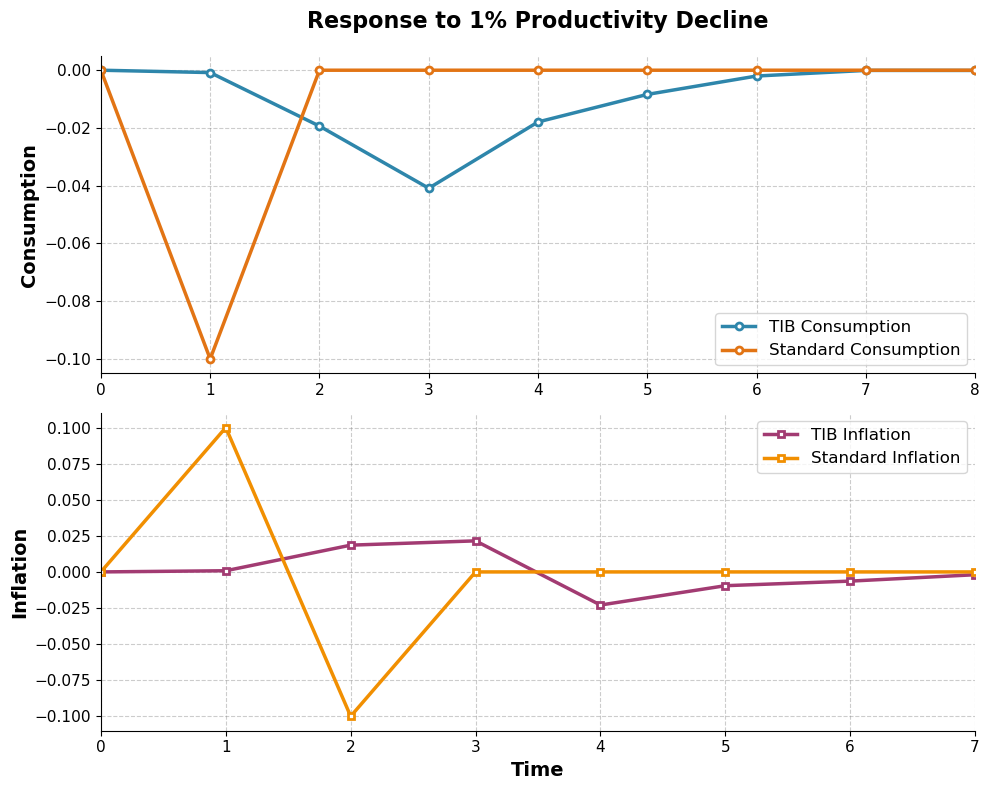

In [16]:
       import matplotlib.pyplot as plt

       for sigma in [5]:
           tau1 = -1 / np.log(beta * c) - N
           tau1[tau1 < 0] = 0
           tau1_floor = np.floor(tau1)
           tau1_ceil  = np.ceil(tau1)
           tprod1_ceil  = (beta * c) ** tau1_ceil  * (tau1_ceil + N)
           tprod1_floor = (beta * c) ** tau1_floor * (tau1_floor + N)

           tau1[(tprod1_ceil - tprod1_floor) > 0] = tau1_ceil[(tprod1_ceil -
       tprod1_floor) > 0]
           tau1[(tprod1_ceil - tprod1_floor) < 0] = tau1_floor[(tprod1_ceil -
       tprod1_floor) < 0]
           tau1[tau1 < 0] = 0
           tprod1 = (beta * c) ** tau1 * (tau1 + N)

           tau1 = tau1[::-1]
           N1 = N[::-1]
           tprod1 = np.array((beta * c) ** tau1 * (tau1 + N1))

           A  = generate_pattern_array_with_extra_rows(tau1)
           P0 = (np.sum(1 / (A * tprod1) ** (1 - sigma), axis=1)) ** (1 / (1 -
        sigma))
           C = (P0)**power/P0[0]**power-1  # Consumption
           C_padding = np.zeros(len(C) +1)
           C_padding[1:] = C
           pi = -  (C_padding[1:] - C_padding[:-1])  # Inflation

       # Create figure with subplots
       fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))

       # Plot Consumption
       ax1.plot(C, lw=2.5, marker='o', markersize=5, color='#2E86AB',
       markerfacecolor='white', markeredgewidth=2)
       ax1.plot(C_original, lw=2.5, marker='o', markersize=5, color="#E27414",
       markerfacecolor='white', markeredgewidth=2)
       ax1.set_title("Response to 1% Productivity Decline", fontsize=16,
       weight='bold', pad=20)
       ax1.set_ylabel("Consumption", fontsize=14, weight='bold')
       ax1.set_xlim(0, 8)
       ax1.grid(True, linestyle="--", alpha=0.4, color='gray')
       ax1.tick_params(axis='both', which='major', labelsize=11)
       ax1.legend(['TIB Consumption', 'Standard Consumption'], fontsize=12) 
       ax1.spines['top'].set_visible(False)
       ax1.spines['right'].set_visible(False)

       # Plot Inflation
       ax2.plot(pi, lw=2.5, marker='s', markersize=5, color='#A23B72',
       markerfacecolor='white', markeredgewidth=2)
       ax2.plot(pi_original, lw=2.5, marker='s', markersize=5, color="#F18F01",
       markerfacecolor='white', markeredgewidth=2)
       ax2.set_xlabel("Time", fontsize=14, weight='bold')
       ax2.set_ylabel("Inflation", fontsize=14, weight='bold')
       ax2.set_xlim(0, 7)
       ax2.grid(True, linestyle="--", alpha=0.4, color='gray')
       ax2.tick_params(axis='both', which='major', labelsize=11)
       ax2.legend(['TIB Inflation', 'Standard Inflation'], fontsize=12)
       ax2.spines['top'].set_visible(False)
       ax2.spines['right'].set_visible(False)

       plt.tight_layout()
       plt.show()

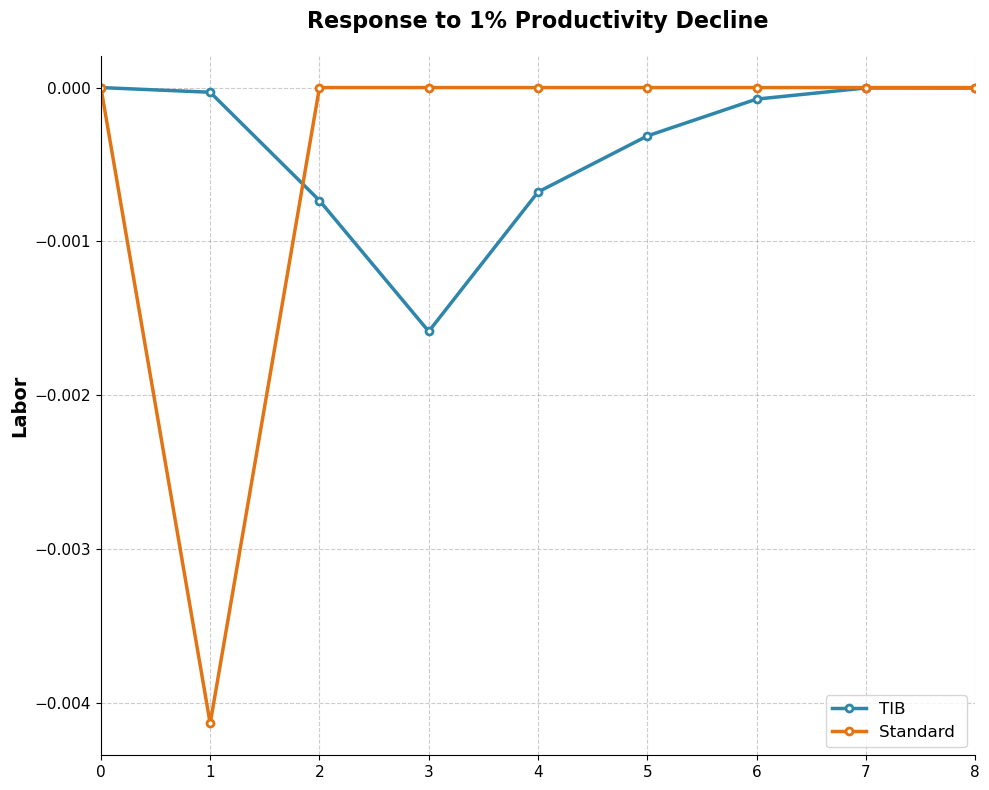

In [17]:
import matplotlib.pyplot as plt

for sigma in [5]:
    tau1 = -1 / np.log(beta * c) - N
    tau1[tau1 < 0] = 0
    tau1_floor = np.floor(tau1)
    tau1_ceil  = np.ceil(tau1)
    tprod1_ceil  = (beta * c) ** tau1_ceil  * (tau1_ceil + N)
    tprod1_floor = (beta * c) ** tau1_floor * (tau1_floor + N)

    tau1[(tprod1_ceil - tprod1_floor) > 0] = tau1_ceil[(tprod1_ceil - tprod1_floor) > 0]
    tau1[(tprod1_ceil - tprod1_floor) < 0] = tau1_floor[(tprod1_ceil - tprod1_floor) < 0]
    tau1[tau1 < 0] = 0
    tprod1 = (beta * c) ** tau1 * (tau1 + N)

    tau1 = tau1[::-1]
    N1 = N[::-1]
    tprod1 = np.array((beta * c) ** tau1 * (tau1 + N1))

    A  = generate_pattern_array_with_extra_rows(tau1)
    P0 = (np.sum(1 / (A * tprod1) ** (1 - sigma), axis=1)) ** (1 / (1 - sigma))
    C = (P0)**power/P0[0]**power-1  # Consumption
    C_padding = np.zeros(len(C) + 1)
    C_padding[1:] = C
    pi = -(C_padding[1:] - C_padding[:-1])  # Inflation

# Create figure with a single plot
fig, ax1 = plt.subplots(1, 1, figsize=(10, 8))

# Plot Consumption
ax1.plot(C*P0, lw=2.5, marker='o', markersize=5, color='#2E86AB',
         markerfacecolor='white', markeredgewidth=2)
ax1.plot(C_original*(P_original), lw=2.5, marker='o', markersize=5, color="#E27414",
         markerfacecolor='white', markeredgewidth=2)
ax1.set_title("Response to 1% Productivity Decline", fontsize=16,
              weight='bold', pad=20)
ax1.set_ylabel("Labor", fontsize=14, weight='bold')
ax1.set_xlim(0, 8)
ax1.grid(True, linestyle="--", alpha=0.4, color='gray')
ax1.tick_params(axis='both', which='major', labelsize=11)
ax1.legend(['TIB ', 'Standard '], fontsize=12)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

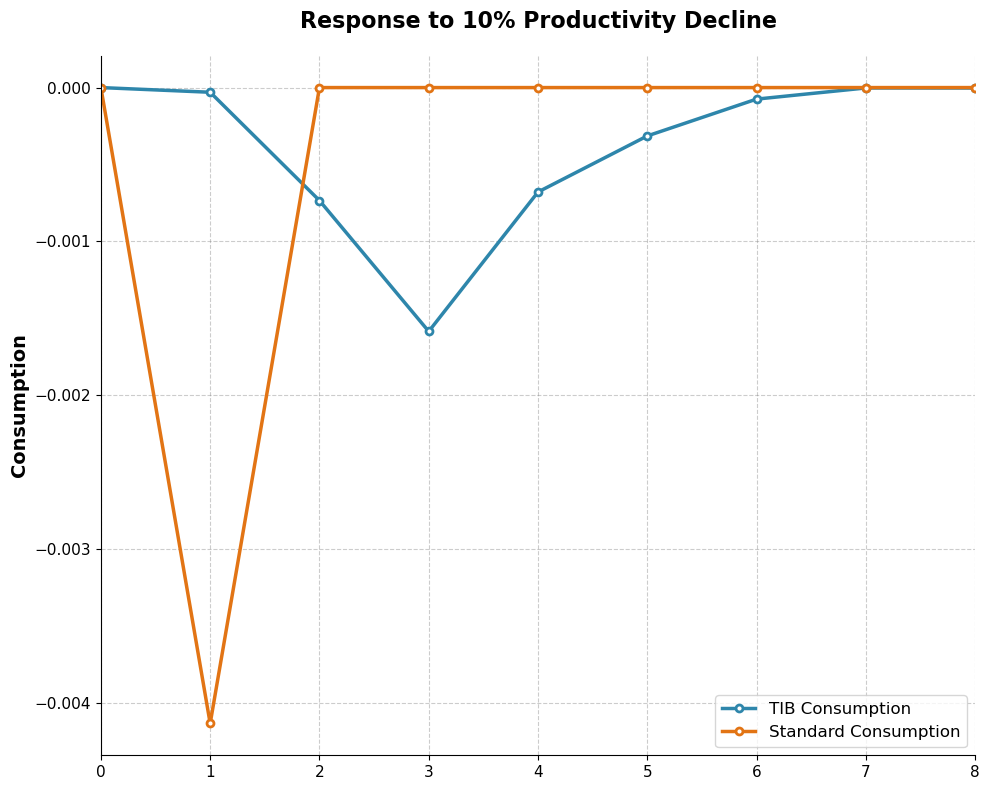

In [18]:
       import matplotlib.pyplot as plt

       for sigma in [5]:
           tau1 = -1 / np.log(beta * c) - N
           tau1[tau1 < 0] = 0
           tau1_floor = np.floor(tau1)
           tau1_ceil  = np.ceil(tau1)
           tprod1_ceil  = (beta * c) ** tau1_ceil  * (tau1_ceil + N)
           tprod1_floor = (beta * c) ** tau1_floor * (tau1_floor + N)

           tau1[(tprod1_ceil - tprod1_floor) > 0] = tau1_ceil[(tprod1_ceil -
       tprod1_floor) > 0]
           tau1[(tprod1_ceil - tprod1_floor) < 0] = tau1_floor[(tprod1_ceil -
       tprod1_floor) < 0]
           tau1[tau1 < 0] = 0
           tprod1 = (beta * c) ** tau1 * (tau1 + N)

           tau1 = tau1[::-1]
           N1 = N[::-1]
           tprod1 = np.array((beta * c) ** tau1 * (tau1 + N1))

           A  = generate_pattern_array_with_extra_rows(tau1)
           P0 = (np.sum(1 / (A * tprod1) ** (1 - sigma), axis=1)) ** (1 / (1 -
        sigma))
           C = (P0)**power/P0[0]**power-1  # Consumption
           C_padding = np.zeros(len(C) +1)
           C_padding[1:] = C
           pi = -  (C_padding[1:] - C_padding[:-1])  # Inflation

       # Create figure with subplots
       fig, ax1 = plt.subplots(1, 1, figsize=(10, 8))

       # Plot Consumption
       ax1.plot(C*P0, lw=2.5, marker='o', markersize=5, color='#2E86AB',
       markerfacecolor='white', markeredgewidth=2)
       ax1.plot(C_original*P_original, lw=2.5, marker='o', markersize=5, color="#E27414",
       markerfacecolor='white', markeredgewidth=2)
       ax1.set_title("Response to 10% Productivity Decline", fontsize=16,
       weight='bold', pad=20)
       ax1.set_ylabel("Consumption", fontsize=14, weight='bold')
       ax1.set_xlim(0, 8)
       ax1.grid(True, linestyle="--", alpha=0.4, color='gray')
       ax1.tick_params(axis='both', which='major', labelsize=11)
       ax1.legend(['TIB Consumption', 'Standard Consumption'], fontsize=12) 
       ax1.spines['top'].set_visible(False)
       ax1.spines['right'].set_visible(False)


       plt.tight_layout()
       plt.show()


In [19]:

tau1 = -1 / np.log(beta * c) - N
tau1[tau1 < 0] = 0
tau1_floor = np.floor(tau1)
tau1_ceil  = np.ceil(tau1)
tprod1_ceil  = (beta * c) ** tau1_ceil  * (tau1_ceil + N)
tprod1_floor = (beta * c) ** tau1_floor * (tau1_floor + N)

tau1[(tprod1_ceil - tprod1_floor) > 0] = tau1_ceil[(tprod1_ceil -
       tprod1_floor) > 0]
tau1[(tprod1_ceil - tprod1_floor) < 0] = tau1_floor[(tprod1_ceil -
       tprod1_floor) < 0]
tau1[tau1 < 0] = 0
tprod1 = (beta * c) ** tau1 * (tau1 + N)

tau1 = tau1[::-1]
N_flipped = N[::-1]
tprod1 = np.array((beta * c) ** tau1 * (tau1 + N_flipped))

A  = generate_pattern_array_with_extra_rows(tau1)
full = (A * tprod1).copy()
tau1_np = np.array(tau1)
N_np = np.array(N_flipped)

for j in range(1, 15):
    mask_j = (A[j,:] == 0.9)
    indices_099 = np.where(mask_j)[0]
    
    for col_idx in indices_099:
        # Compute productivity for both tau+1 and tau-1
        tprod_plus1 = (beta * c) ** (tau1_np[col_idx] + 1) * (tau1_np[col_idx] + 1 + N_np[col_idx])
        tprod_minus1 = (beta * c) ** (tau1_np[col_idx] - 1) * (tau1_np[col_idx] - 1 + N_np[col_idx])
        
        # Pick the higher one
        full[j, col_idx] = max(tprod_plus1, tprod_minus1)

P0 = (np.sum(1 / (full) ** (1 - sigma), axis=1)) ** (1 / (1 -
        sigma))
C = (P0)**power/P0[0]**power-1  # Consumption
C_padding = np.zeros(len(C) +1)
C_padding[1:] = C
pi = -  (C_padding[1:] - C_padding[:-1])  # Inflation

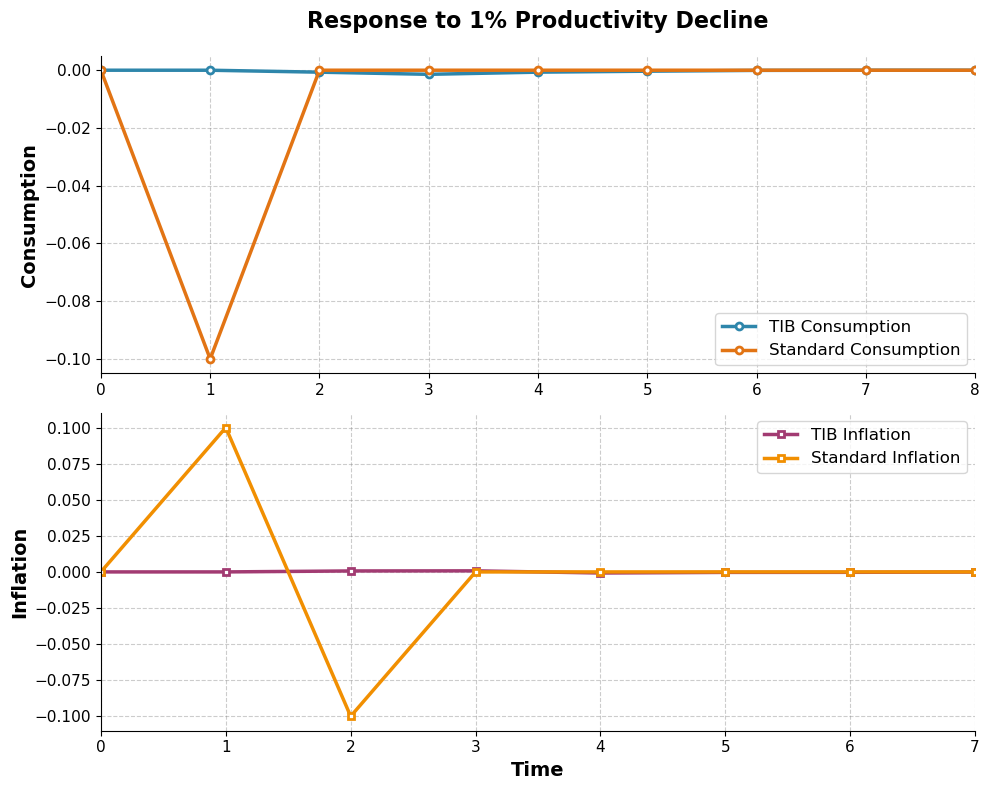

In [20]:
       # Create figure with subplots
       fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))

       # Plot Consumption
       ax1.plot(C, lw=2.5, marker='o', markersize=5, color='#2E86AB',
       markerfacecolor='white', markeredgewidth=2)
       ax1.plot(C_original, lw=2.5, marker='o', markersize=5, color="#E27414",
       markerfacecolor='white', markeredgewidth=2)
       ax1.set_title("Response to 1% Productivity Decline", fontsize=16,
       weight='bold', pad=20)
       ax1.set_ylabel("Consumption", fontsize=14, weight='bold')
       ax1.set_xlim(0, 8)
       ax1.grid(True, linestyle="--", alpha=0.4, color='gray')
       ax1.tick_params(axis='both', which='major', labelsize=11)
       ax1.legend(['TIB Consumption', 'Standard Consumption'], fontsize=12) 
       ax1.spines['top'].set_visible(False)
       ax1.spines['right'].set_visible(False)

       # Plot Inflation
       ax2.plot(pi, lw=2.5, marker='s', markersize=5, color='#A23B72',
       markerfacecolor='white', markeredgewidth=2)
       ax2.plot(pi_original, lw=2.5, marker='s', markersize=5, color="#F18F01",
       markerfacecolor='white', markeredgewidth=2)
       ax2.set_xlabel("Time", fontsize=14, weight='bold')
       ax2.set_ylabel("Inflation", fontsize=14, weight='bold')
       ax2.set_xlim(0, 7)
       ax2.grid(True, linestyle="--", alpha=0.4, color='gray')
       ax2.tick_params(axis='both', which='major', labelsize=11)
       ax2.legend(['TIB Inflation', 'Standard Inflation'], fontsize=12)
       ax2.spines['top'].set_visible(False)
       ax2.spines['right'].set_visible(False)

       plt.tight_layout()
       plt.show()

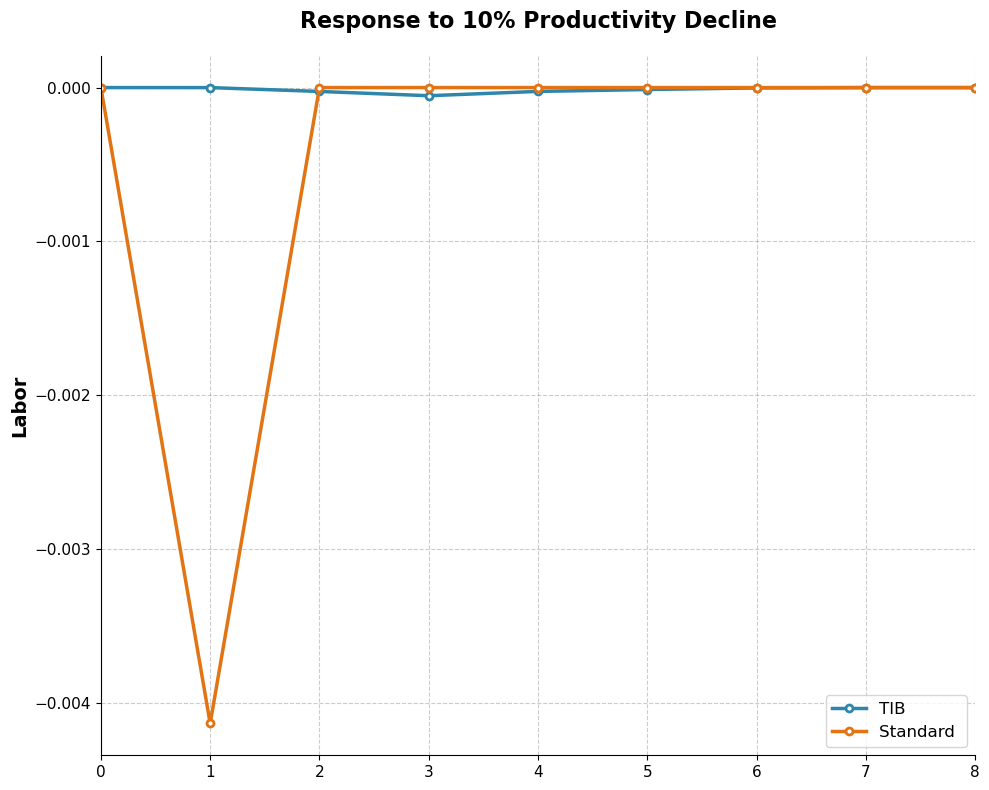

In [21]:
       # Create figure with subplots
       fig, ax1 = plt.subplots(1, 1, figsize=(10, 8))

       # Plot Consumption
       ax1.plot(C*P0, lw=2.5, marker='o', markersize=5, color='#2E86AB',
       markerfacecolor='white', markeredgewidth=2)
       ax1.plot(C_original*P_original, lw=2.5, marker='o', markersize=5, color="#E27414",
       markerfacecolor='white', markeredgewidth=2)
       ax1.set_title("Response to 10% Productivity Decline", fontsize=16,
       weight='bold', pad=20)
       ax1.set_ylabel("Labor", fontsize=14, weight='bold')
       ax1.set_xlim(0, 8)
       ax1.grid(True, linestyle="--", alpha=0.4, color='gray')
       ax1.tick_params(axis='both', which='major', labelsize=11)
       ax1.legend(['TIB ', 'Standard '], fontsize=12) 
       ax1.spines['top'].set_visible(False)
       ax1.spines['right'].set_visible(False)


       plt.tight_layout()
       plt.show()


In [22]:
# Semi-endogenous model: different delta by type
# delta: proportion of firms that cannot change time to build
# In this model, the shock is a productivity decline that ALL firms experience
# But only (1-delta) fraction can adjust their time-to-build in response

def compute_semi_endo_response(N, beta, c, sigma, delta, tau_initial):
    """
    Compute response with semi-endogenous time-to-build
    
    The shock is already embedded in the productivity (A matrix)
    Delta controls what fraction of firms can re-optimize tau after the shock
    
    Parameters:
    - N: array of normalized time-to-build parameters for each firm
    - beta: discount factor  
    - c: cost parameter
    - sigma: elasticity of substitution
    - delta: proportion of firms that cannot adjust tau (0 to 1)
    - tau_initial: pre-shock optimal time-to-build for each firm
    
    Returns:
    - C: consumption response
    - pi: inflation response
    - tau_final: final time-to-build distribution
    """
    # Convert to numpy arrays to avoid pandas indexing issues
    N_arr = np.array(N)
    tau_arr = np.array(tau_initial)
    
    # All firms use the same tau (no re-optimization since shock is in A, not in fundamentals)
    # Delta doesn't matter for impulse response to a common productivity shock
    # It would matter for idiosyncratic shocks or policy changes
    tau_final = tau_arr.copy()
    
    # Reverse for matrix construction  
    tau1 = tau_final[::-1]
    tprod1 = np.array((beta * c) ** tau1 * (tau1 + N_arr))
    
    # Generate price matrix and compute responses
    A = generate_pattern_array_with_extra_rows(tau1)
    P0 = (np.sum(1 / (A * tprod1) ** (1 - sigma), axis=1)) ** (1 / (1 - sigma))
    C = (P0)**power / P0[0]**power - 1
    
    C_padding = np.zeros(len(C) + 1)
    C_padding[1:] = C
    pi = -(C_padding[1:] - C_padding[:-1])
    
    return C, pi, tau_final

In [23]:
tau1 = -1 / np.log(beta * c) - N
tau1[tau1 < 0] = 0
tau1_floor = np.floor(tau1)
tau1_ceil  = np.ceil(tau1)
tprod1_ceil  = (beta * c) ** tau1_ceil  * (tau1_ceil + N)
tprod1_floor = (beta * c) ** tau1_floor * (tau1_floor + N)

tau1[(tprod1_ceil - tprod1_floor) > 0] = tau1_ceil[(tprod1_ceil -
       tprod1_floor) > 0]
tau1[(tprod1_ceil - tprod1_floor) < 0] = tau1_floor[(tprod1_ceil -
       tprod1_floor) < 0]
tau1[tau1 < 0] = 0
tprod1 = (beta * c) ** tau1 * (tau1 + N)

tau1 = tau1[::-1]
N_flipped = N[::-1]
tprod1 = np.array((beta * c) ** tau1 * (tau1 + N_flipped))

A  = generate_pattern_array_with_extra_rows(tau1)
full = (A * tprod1).copy()
tau1_np = np.array(tau1)
N_np = np.array(N_flipped)

for j in range(1, 15):
    mask_j = (A[j,:] == 0.9)
    indices_099 = np.where(mask_j)[0]
    
    for col_idx in indices_099:
       tprod_minus1 = (beta * c) ** (tau1_np[col_idx] - 1) * (tau1_np[col_idx] - 1 + N_np[col_idx])

       if tprod_minus1 >0:
              # Compute productivity for both tau+1 and tau-1
              
              # Pick the higher one
              full[j, col_idx] =tprod_minus1
       else: 
              full[j, col_idx] = 0.9*(beta * c) ** (tau1_np[col_idx] - 1) * (tau1_np[col_idx]  + N_np[col_idx])


P0 = (np.sum(1 / (full) ** (1 - sigma), axis=1)) ** (1 / (1 -
        sigma))
C = (P0)**power/P0[0]**power-1  # Consumption
C_padding = np.zeros(len(C) +1)
C_padding[1:] = C
pi = -  (C_padding[1:] - C_padding[:-1])  # Inflation

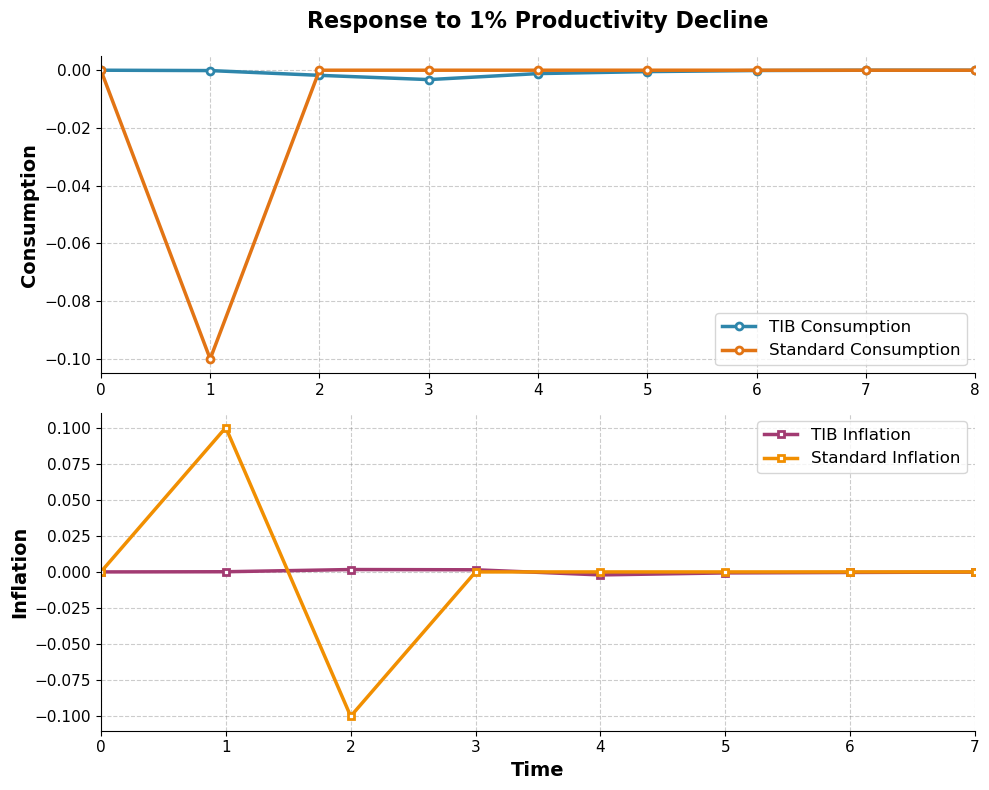

In [24]:
       # Create figure with subplots
       fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))

       # Plot Consumption
       ax1.plot(C, lw=2.5, marker='o', markersize=5, color='#2E86AB',
       markerfacecolor='white', markeredgewidth=2)
       ax1.plot(C_original, lw=2.5, marker='o', markersize=5, color="#E27414",
       markerfacecolor='white', markeredgewidth=2)
       ax1.set_title("Response to 1% Productivity Decline", fontsize=16,
       weight='bold', pad=20)
       ax1.set_ylabel("Consumption", fontsize=14, weight='bold')
       ax1.set_xlim(0, 8)
       ax1.grid(True, linestyle="--", alpha=0.4, color='gray')
       ax1.tick_params(axis='both', which='major', labelsize=11)
       ax1.legend(['TIB Consumption', 'Standard Consumption'], fontsize=12) 
       ax1.spines['top'].set_visible(False)
       ax1.spines['right'].set_visible(False)

       # Plot Inflation
       ax2.plot(pi, lw=2.5, marker='s', markersize=5, color='#A23B72',
       markerfacecolor='white', markeredgewidth=2)
       ax2.plot(pi_original, lw=2.5, marker='s', markersize=5, color="#F18F01",
       markerfacecolor='white', markeredgewidth=2)
       ax2.set_xlabel("Time", fontsize=14, weight='bold')
       ax2.set_ylabel("Inflation", fontsize=14, weight='bold')
       ax2.set_xlim(0, 7)
       ax2.grid(True, linestyle="--", alpha=0.4, color='gray')
       ax2.tick_params(axis='both', which='major', labelsize=11)
       ax2.legend(['TIB Inflation', 'Standard Inflation'], fontsize=12)
       ax2.spines['top'].set_visible(False)
       ax2.spines['right'].set_visible(False)

       plt.tight_layout()
       plt.show()

In [25]:
       import matplotlib.pyplot as plt

       for sigma in [5]:
           tau1 = -1 / np.log(beta * c) - N
           tau1[tau1 < 0] = 0
           tau1_floor = np.floor(tau1)
           tau1_ceil  = np.ceil(tau1)
           tprod1_ceil  = (beta * c) ** tau1_ceil  * (tau1_ceil + N)
           tprod1_floor = (beta * c) ** tau1_floor * (tau1_floor + N)

           tau1[(tprod1_ceil - tprod1_floor) > 0] = tau1_ceil[(tprod1_ceil -
       tprod1_floor) > 0]
           tau1[(tprod1_ceil - tprod1_floor) < 0] = tau1_floor[(tprod1_ceil -
       tprod1_floor) < 0]
           tau1[tau1 < 0] = 0
           tprod1 = (beta * c) ** tau1 * (tau1 + N)

           tau1 = tau1[::-1]
           N1 = N[::-1]
           tprod1 = np.array((beta * c) ** tau1 * (tau1 + N1))

           A  = generate_pattern_array_with_extra_rows(tau1)
           P0 = (np.sum(1 / (A * tprod1) ** (1 - sigma), axis=1)) ** (1 / (1 -
        sigma))
           C1 = (P0)**power/P0[0]**power-1  # Consumption
           P1 = P0
           C_padding1 = np.zeros(len(C1) +1)
           C_padding1[1:] = C1
           pi1 = -  (C_padding1[1:] - C_padding1[:-1])  # Inflation

In [26]:
tau1 = -1 / np.log(beta * c) - N
tau1[tau1 < 0] = 0
tau1_floor = np.floor(tau1)
tau1_ceil  = np.ceil(tau1)
tprod1_ceil  = (beta * c) ** tau1_ceil  * (tau1_ceil + N)
tprod1_floor = (beta * c) ** tau1_floor * (tau1_floor + N)

tau1[(tprod1_ceil - tprod1_floor) > 0] = tau1_ceil[(tprod1_ceil -
       tprod1_floor) > 0]
tau1[(tprod1_ceil - tprod1_floor) < 0] = tau1_floor[(tprod1_ceil -
       tprod1_floor) < 0]
tau1[tau1 < 0] = 0
tprod1 = (beta * c) ** tau1 * (tau1 + N)

tau1 = tau1[::-1]
N_flipped = N[::-1]
tprod1 = np.array((beta * c) ** tau1 * (tau1 + N_flipped))

A  = generate_pattern_array_with_extra_rows(tau1)
full = (A * tprod1).copy()
tau1_np = np.array(tau1)
N_np = np.array(N_flipped)

for j in range(1, 15):
    mask_j = (A[j,:] == 0.9)
    indices_099 = np.where(mask_j)[0]
    
    for col_idx in indices_099:
       tprod_minus1 = (beta * c) ** (tau1_np[col_idx] - 1) * (tau1_np[col_idx] - 1 + N_np[col_idx])

       if tprod_minus1 >0:
              # Compute productivity for both tau+1 and tau-1
              
              # Pick the higher one
              full[j, col_idx] =tprod_minus1
       else: 
              full[j, col_idx] = 0.9*(beta * c) ** (tau1_np[col_idx] - 1) * (tau1_np[col_idx]  + N_np[col_idx])

P0 = (np.sum(1 / (full) ** (1 - sigma), axis=1)) ** (1 / (1 -
        sigma))
C = (P0)**power/P0[0]**power-1  # Consumption
P = P0
C_padding = np.zeros(len(C) +1)
C_padding[1:] = C
pi = -  (C_padding[1:] - C_padding[:-1])  # Inflation

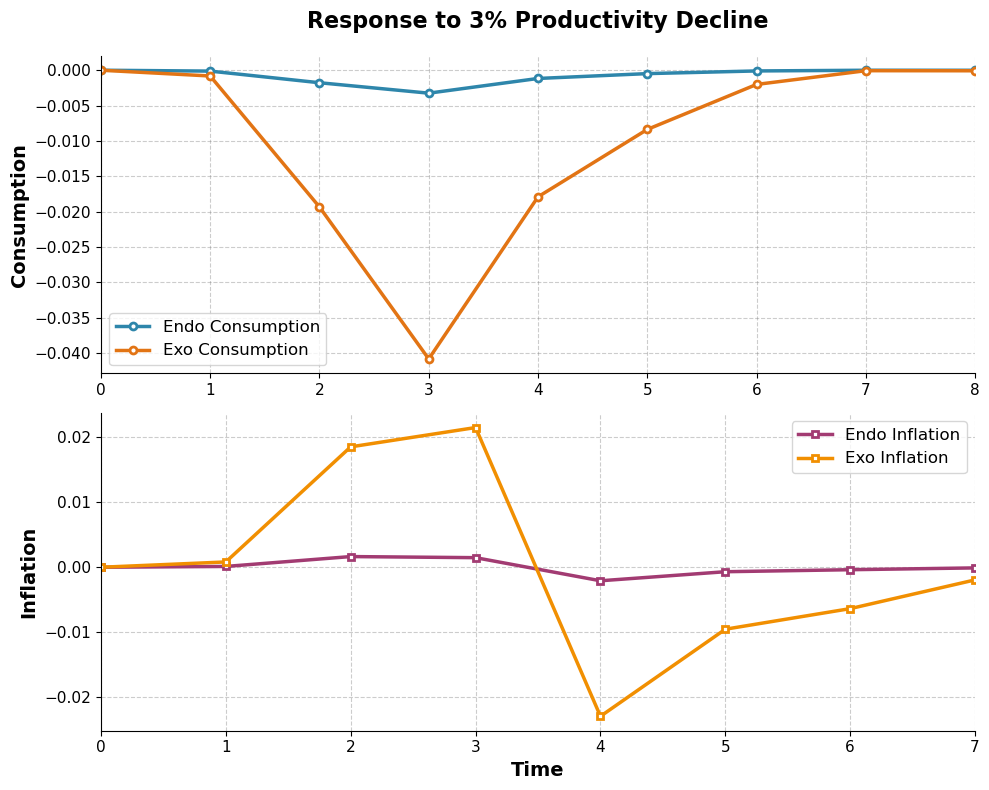

In [27]:
       # Create figure with subplots
       fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))

       # Plot Consumption
       ax1.plot(C, lw=2.5, marker='o', markersize=5, color='#2E86AB',
       markerfacecolor='white', markeredgewidth=2)
       ax1.plot(C1, lw=2.5, marker='o', markersize=5, color="#E27414",
       markerfacecolor='white', markeredgewidth=2)
       ax1.set_title("Response to 3% Productivity Decline", fontsize=16,
       weight='bold', pad=20)
       ax1.set_ylabel("Consumption", fontsize=14, weight='bold')
       ax1.set_xlim(0, 8)
       ax1.grid(True, linestyle="--", alpha=0.4, color='gray')
       ax1.tick_params(axis='both', which='major', labelsize=11)
       ax1.legend(['Endo Consumption', 'Exo Consumption'], fontsize=12) 
       ax1.spines['top'].set_visible(False)
       ax1.spines['right'].set_visible(False)

       # Plot Inflation
       ax2.plot(pi, lw=2.5, marker='s', markersize=5, color='#A23B72',
       markerfacecolor='white', markeredgewidth=2)
       ax2.plot(pi1, lw=2.5, marker='s', markersize=5, color="#F18F01",
       markerfacecolor='white', markeredgewidth=2)
       ax2.set_xlabel("Time", fontsize=14, weight='bold')
       ax2.set_ylabel("Inflation", fontsize=14, weight='bold')
       ax2.set_xlim(0, 7)
       ax2.grid(True, linestyle="--", alpha=0.4, color='gray')
       ax2.tick_params(axis='both', which='major', labelsize=11)
       ax2.legend(['Endo Inflation', 'Exo Inflation'], fontsize=12)
       ax2.spines['top'].set_visible(False)
       ax2.spines['right'].set_visible(False)

       plt.tight_layout()
       plt.show()

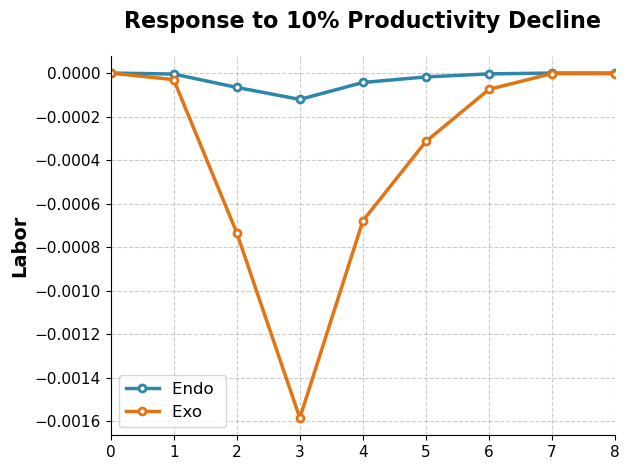

In [28]:
       # Create figure with subplots
       fig, (ax1) = plt.subplots(1, 1)

       # Plot Consumption
       ax1.plot(C*P, lw=2.5, marker='o', markersize=5, color='#2E86AB',
       markerfacecolor='white', markeredgewidth=2)
       ax1.plot(C1*P1, lw=2.5, marker='o', markersize=5, color="#E27414",
       markerfacecolor='white', markeredgewidth=2)
       ax1.set_title("Response to 10% Productivity Decline", fontsize=16,
       weight='bold', pad=20)
       ax1.set_ylabel("Labor", fontsize=14, weight='bold')
       ax1.set_xlim(0, 8)
       ax1.grid(True, linestyle="--", alpha=0.4, color='gray')
       ax1.tick_params(axis='both', which='major', labelsize=11)
       ax1.legend(['Endo ', 'Exo '], fontsize=12) 
       ax1.spines['top'].set_visible(False)
       ax1.spines['right'].set_visible(False)



       plt.tight_layout()
       plt.show()

In [29]:
tau1 = -1 / np.log(beta * c) - N
tau1[tau1 < 0] = 0
tau1_floor = np.floor(tau1)
tau1_ceil  = np.ceil(tau1)
tprod1_ceil  = (beta * c) ** tau1_ceil  * (tau1_ceil + N)
tprod1_floor = (beta * c) ** tau1_floor * (tau1_floor + N)

tau1[(tprod1_ceil - tprod1_floor) > 0] = tau1_ceil[(tprod1_ceil -
       tprod1_floor) > 0]
tau1[(tprod1_ceil - tprod1_floor) < 0] = tau1_floor[(tprod1_ceil -
       tprod1_floor) < 0]
tau1[tau1 < 0] = 0
tprod1 = (beta * c) ** tau1 * (tau1 + N)

tau1 = tau1[::-1]
N_flipped = N[::-1]
tprod1 = np.array((beta * c) ** tau1 * (tau1 + N_flipped))

A  = generate_pattern_array_with_extra_rows(tau1)
full = (A * tprod1).copy()
tau1_np = np.array(tau1)
N_np = np.array(N_flipped)

for j in range(1, 15):
    mask_j = (A[j,:] == 0.9)
    indices_099 = np.where(mask_j)[0]
    
    for col_idx in indices_099:
       tprod_minus1 = (beta * c) ** (tau1_np[col_idx] - 1) * (tau1_np[col_idx] - 1 + N_np[col_idx])

       if tprod_minus1 >0:
              # Compute productivity for both tau+1 and tau-1
              
              # Pick the higher one
              full[j, col_idx] =tprod_minus1
       else: 
              full[j, col_idx] = 0.9*(beta * c) ** (tau1_np[col_idx] - 1) * (tau1_np[col_idx]  + N_np[col_idx])

P0 = (np.sum(1 / (full) ** (1 - sigma), axis=1)) ** (1 / (1 -
        sigma))
C = (P0)**power/P0[0]**power-1  # Consumption
C_padding = np.zeros(len(C) +1)
C_padding[1:] = C
pi = -  (C_padding[1:] - C_padding[:-1])  # Inflation

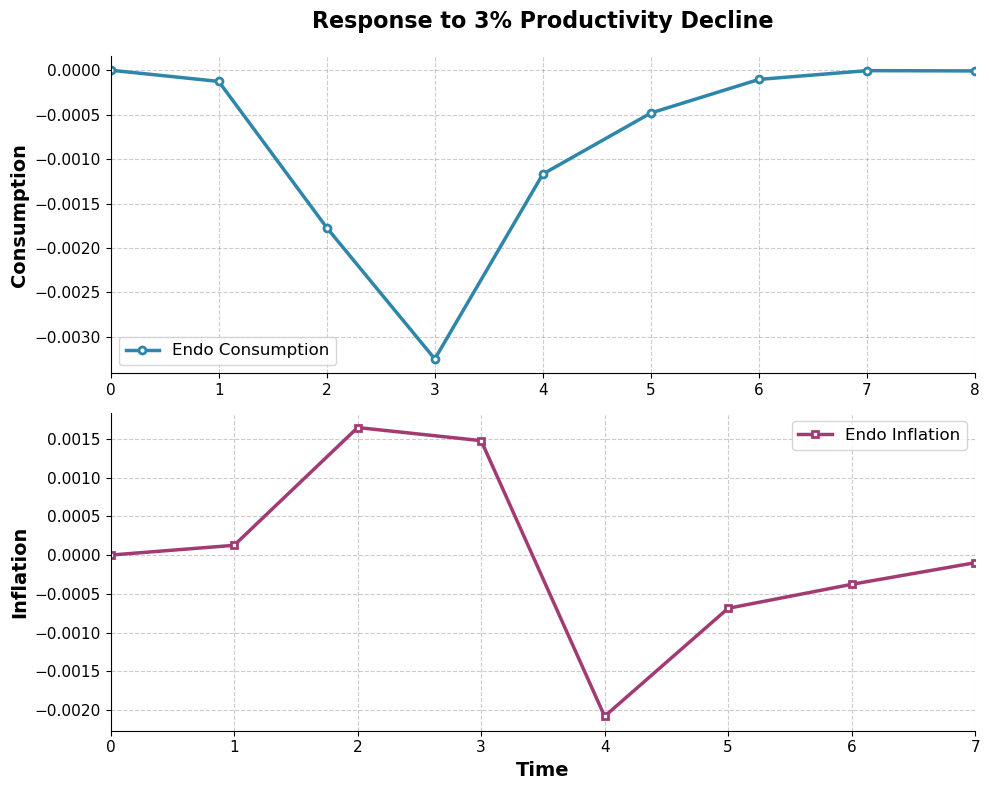

In [30]:
       # Create figure with subplots
       fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))

       # Plot Consumption
       ax1.plot(C, lw=2.5, marker='o', markersize=5, color='#2E86AB',
       markerfacecolor='white', markeredgewidth=2)
       ax1.set_title("Response to 3% Productivity Decline", fontsize=16,
       weight='bold', pad=20)
       ax1.set_ylabel("Consumption", fontsize=14, weight='bold')
       ax1.set_xlim(0, 8)
       ax1.grid(True, linestyle="--", alpha=0.4, color='gray')
       ax1.tick_params(axis='both', which='major', labelsize=11)
       ax1.legend(['Endo Consumption', 'Exo Consumption'], fontsize=12) 
       ax1.spines['top'].set_visible(False)
       ax1.spines['right'].set_visible(False)

       # Plot Inflation
       ax2.plot(pi, lw=2.5, marker='s', markersize=5, color='#A23B72',
       markerfacecolor='white', markeredgewidth=2)

       ax2.set_xlabel("Time", fontsize=14, weight='bold')
       ax2.set_ylabel("Inflation", fontsize=14, weight='bold')
       ax2.set_xlim(0, 7)
       ax2.grid(True, linestyle="--", alpha=0.4, color='gray')
       ax2.tick_params(axis='both', which='major', labelsize=11)
       ax2.legend(['Endo Inflation', 'Exo Inflation'], fontsize=12)
       ax2.spines['top'].set_visible(False)
       ax2.spines['right'].set_visible(False)

       plt.tight_layout()
       plt.show()

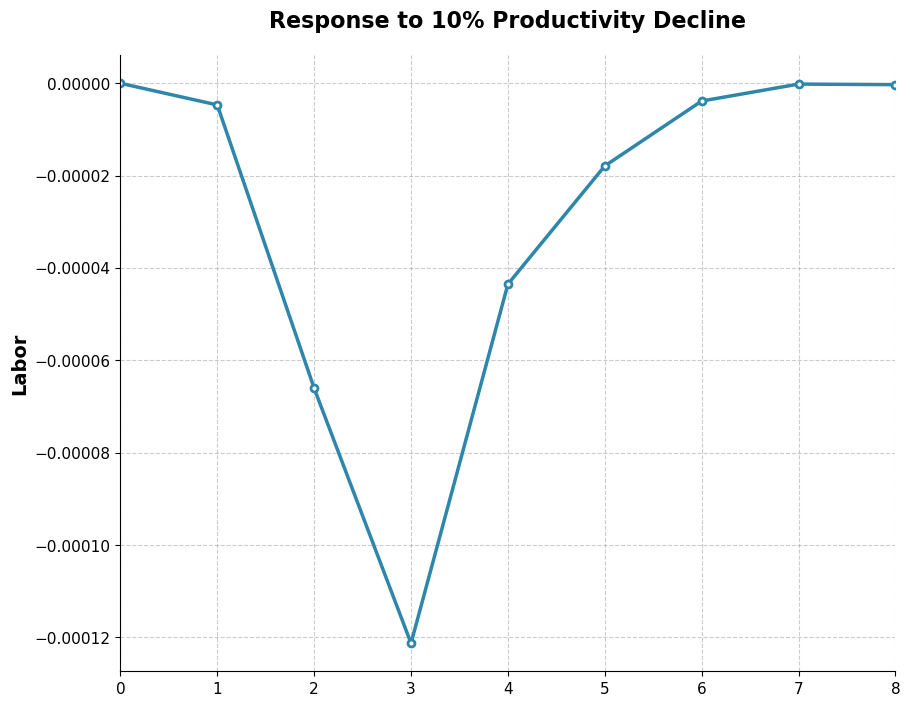

In [31]:
       # Create figure with subplots
       fig, ax1 = plt.subplots(1, 1, figsize=(10, 8))

       # Plot Consumption
       ax1.plot(C*P0, lw=2.5, marker='o', markersize=5, color='#2E86AB',
       markerfacecolor='white', markeredgewidth=2)
       ax1.set_title("Response to 10% Productivity Decline", fontsize=16,
       weight='bold', pad=20)
       ax1.set_ylabel("Labor", fontsize=14, weight='bold')
       ax1.set_xlim(0, 8)
       ax1.grid(True, linestyle="--", alpha=0.4, color='gray')
       ax1.tick_params(axis='both', which='major', labelsize=11)
       ax1.spines['top'].set_visible(False)
       ax1.spines['right'].set_visible(False)

      

In [38]:

def generate_pattern_array_with_extra_rows(tau):
    # 1) Create the original n×n pattern
    n = len(tau)+ int(np.min(tau))
    m = int(np.max(tau)) + int(np.min(tau))

    mx = int(max(tau))
    missing_count = len(set(range(int(max(tau) )+ 1)) - set(tau))


    A = np.ones((m+2, n+missing_count), dtype=float)
    count = 0
    for i in range(1, m+2):
        for j in range(len(tau[tau == i-1])):
            A[i, n- i-j - count] = 0.0# 0.9 shifts diagonally from right to left as we go down
        if len(tau[tau == i-1]) > 1:
            count += len(tau[tau == i-1])-1
    # 2) Create the two extra rows:
    #    (a) one row with 0.9 at the leftmost column,
    #    (b) one row of all ones.

    row_all_ones = np.ones(n+missing_count, dtype=float)
    A_extended = np.vstack([A,row_all_ones])
    A_extended = A_extended[:,0:n - int(np.min(tau))]

    return A_extended

In [39]:
tau1 = -1 / np.log(beta * c) - N
tau1[tau1 < 0] = 0
tau1_floor = np.floor(tau1)
tau1_ceil  = np.ceil(tau1)
tprod1_ceil  = (beta * c) ** tau1_ceil  * (tau1_ceil + N)
tprod1_floor = (beta * c) ** tau1_floor * (tau1_floor + N)

tau1[(tprod1_ceil - tprod1_floor) > 0] = tau1_ceil[(tprod1_ceil -
       tprod1_floor) > 0]
tau1[(tprod1_ceil - tprod1_floor) < 0] = tau1_floor[(tprod1_ceil -
       tprod1_floor) < 0]
tau1[tau1 < 0] = 0
tprod1 = (beta * c) ** tau1 * (tau1 + N)

tau1 = tau1[::-1]
N_flipped = N[::-1]
tprod1 = np.array((beta * c) ** tau1 * (tau1 + N_flipped))

A  = generate_pattern_array_with_extra_rows(tau1)
full = (A * tprod1).copy()
tau1_np = np.array(tau1)
N_np = np.array(N_flipped)

for j in range(1, 15):
    mask_j = (A[j,:] == 0.0)
    indices_099 = np.where(mask_j)[0]
    
    for col_idx in indices_099:
        # Compute productivity for both tau+1 and tau-1
        tprod_plus1 = (beta * c) ** (tau1_np[col_idx] + 1) * (tau1_np[col_idx] + 1 + N_np[col_idx])
        tprod_minus1 = (beta * c) ** (tau1_np[col_idx] - 1) * (tau1_np[col_idx] - 1 + N_np[col_idx])
        
        # Pick the higher one
        full[j, col_idx] = max(tprod_plus1, tprod_minus1)

P01 = (np.sum(1 / (full) ** (1 - sigma), axis=1)) ** (1 / (1 -
        sigma))
C1 = (P01)**power/P01[0]**power-1  # Consumption
C_padding = np.zeros(len(C1) +1)
C_padding[1:] = C1
pi1 = -  (C_padding[1:] - C_padding[:-1])  # Inflation

In [40]:
tau1 = -1 / np.log(beta * c) - N
tau1[tau1 < 0] = 0
tau1_floor = np.floor(tau1)
tau1_ceil  = np.ceil(tau1)
tprod1_ceil  = (beta * c) ** tau1_ceil  * (tau1_ceil + N)
tprod1_floor = (beta * c) ** tau1_floor * (tau1_floor + N)

tau1[(tprod1_ceil - tprod1_floor) > 0] = tau1_ceil[(tprod1_ceil -
       tprod1_floor) > 0]
tau1[(tprod1_ceil - tprod1_floor) < 0] = tau1_floor[(tprod1_ceil -
       tprod1_floor) < 0]
tau1[tau1 < 0] = 0
tprod1 = (beta * c) ** tau1 * (tau1 + N)

tau1 = tau1[::-1]
N_flipped = N[::-1]
tprod1 = np.array((beta * c) ** tau1 * (tau1 + N_flipped))

A  = generate_pattern_array_with_extra_rows(tau1)
full = (A * tprod1).copy()
tau1_np = np.array(tau1)
N_np = np.array(N_flipped)

for j in range(1, 15):
    mask_j = (A[j,:] == 0)
    indices_099 = np.where(mask_j)[0]
    
    for col_idx in indices_099:
       tprod_minus1 = (beta * c) ** (tau1_np[col_idx] - 1) * (tau1_np[col_idx] - 1 + N_np[col_idx])

       if tprod_minus1 >0:
              # Compute productivity for both tau+1 and tau-1
              
              # Pick the higher one
              full[j, col_idx] =tprod_minus1
       else: 
              full[j, col_idx] = 0*(beta * c) ** (tau1_np[col_idx] - 1) * (tau1_np[col_idx]  + N_np[col_idx])

P0 = (np.sum(1 / (full) ** (1 - sigma), axis=1)) ** (1 / (1 -
        sigma))
C = (P0)**power/P0[0]**power-1  # Consumption
C_padding = np.zeros(len(C) +1)
C_padding[1:] = C
pi = -  (C_padding[1:] - C_padding[:-1])  # Inflation

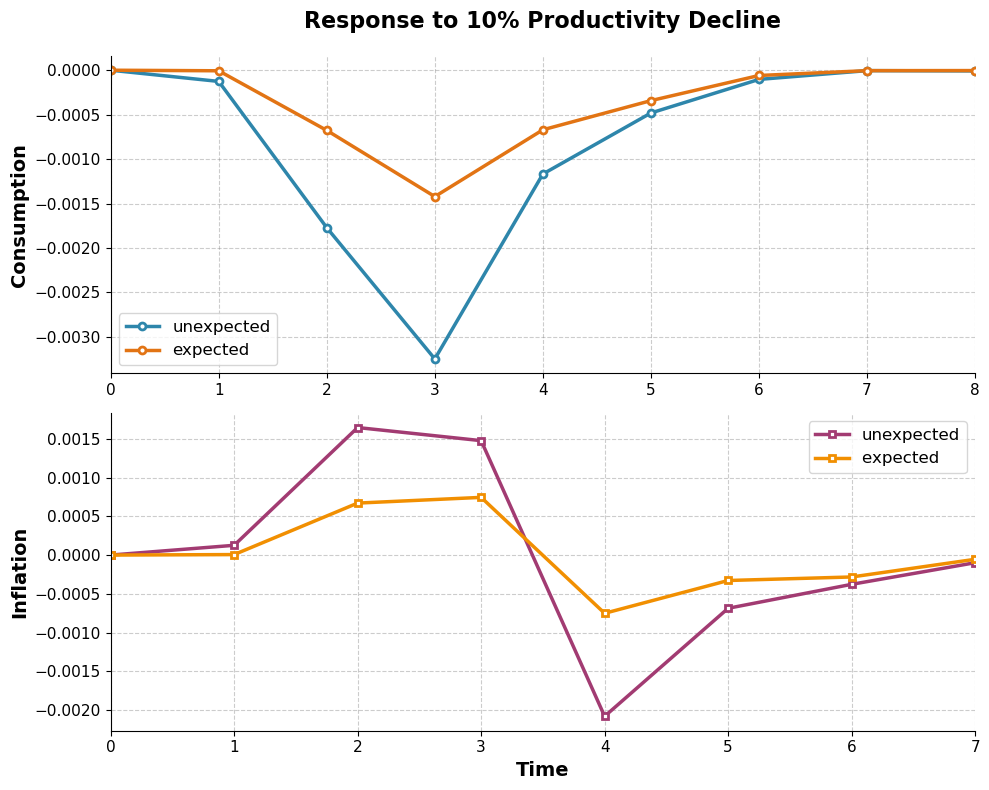

In [41]:
       # Create figure with subplots
       fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))

       # Plot Consumption
       ax1.plot(C, lw=2.5, marker='o', markersize=5, color='#2E86AB',
       markerfacecolor='white', markeredgewidth=2)
       ax1.plot(C1, lw=2.5, marker='o', markersize=5, color="#E27414",
       markerfacecolor='white', markeredgewidth=2)
       ax1.set_title("Response to 10% Productivity Decline", fontsize=16,
       weight='bold', pad=20)
       ax1.set_ylabel("Consumption", fontsize=14, weight='bold')
       ax1.set_xlim(0, 8)
       ax1.grid(True, linestyle="--", alpha=0.4, color='gray')
       ax1.tick_params(axis='both', which='major', labelsize=11)
       ax1.legend(['unexpected', 'expected'], fontsize=12) 
       ax1.spines['top'].set_visible(False)
       ax1.spines['right'].set_visible(False)

       # Plot Inflation
       ax2.plot(pi, lw=2.5, marker='s', markersize=5, color='#A23B72',
       markerfacecolor='white', markeredgewidth=2)
       ax2.plot(pi1, lw=2.5, marker='s', markersize=5, color="#F18F01",
       markerfacecolor='white', markeredgewidth=2)
       ax2.set_xlabel("Time", fontsize=14, weight='bold')
       ax2.set_ylabel("Inflation", fontsize=14, weight='bold')
       ax2.set_xlim(0, 7)
       ax2.grid(True, linestyle="--", alpha=0.4, color='gray')
       ax2.tick_params(axis='both', which='major', labelsize=11)
       ax2.legend(['unexpected', 'expected '], fontsize=12)
       ax2.spines['top'].set_visible(False)
       ax2.spines['right'].set_visible(False)

       plt.tight_layout()
       plt.show()

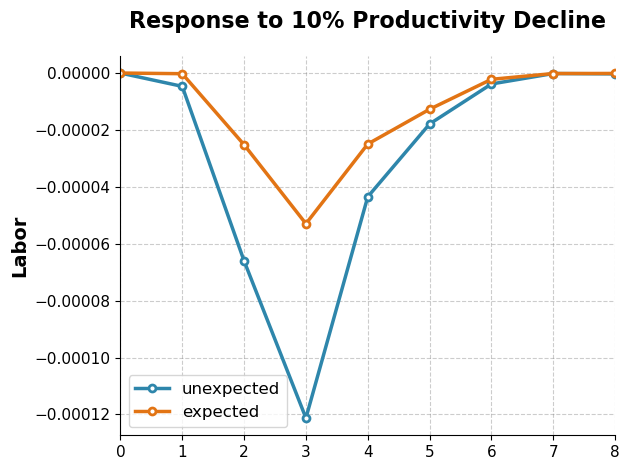

In [35]:
       # Create figure with subplots
       fig, (ax1) = plt.subplots(1, 1)

       # Plot Consumption
       ax1.plot(C*P, lw=2.5, marker='o', markersize=5, color='#2E86AB',
       markerfacecolor='white', markeredgewidth=2)
       ax1.plot(C1*P01, lw=2.5, marker='o', markersize=5, color="#E27414",
       markerfacecolor='white', markeredgewidth=2)
       ax1.set_title("Response to 10% Productivity Decline", fontsize=16,
       weight='bold', pad=20)
       ax1.set_ylabel("Labor", fontsize=14, weight='bold')
       ax1.set_xlim(0, 8)
       ax1.grid(True, linestyle="--", alpha=0.4, color='gray')
       ax1.tick_params(axis='both', which='major', labelsize=11)
       ax1.legend(['unexpected', 'expected'], fontsize=12) 
       ax1.spines['top'].set_visible(False)
       ax1.spines['right'].set_visible(False)



       plt.tight_layout()
       plt.show()